# ⚔️ IPPO competitivo: 2 agentes, movimiento continuo y cubos que hay queubicar en pozos

Dos agentes (**agente A** y **agente B**) comparten una arena de 5×5 con **2 cubos verdes** y **2 pozos**. Cada uno entrena su **propia red PPO**
(*Independent PPO*, IPPO): sin parámetros ni experiencia compartidos; el rival es parte del entorno.

**Acciones continuas.** Cada agente decide a la vez `(ax, ay) ∈ [-1, 1]²`; en cada paso se desplaza `(ax, ay) · VMAX` de `(x0, y0)` a `(x1, y1)`, los dos simultáneamente. La política es una gaussiana aprendida.

**Reglas**
- Los cubos son **más chicos que el pozo** (lado 0.36 vs 0.9): cae cuando su centro entra al pozo. Empiezan en **posiciones al azar en cada episodio**.
- Los agentes empujan cubos (y se empujan entre sí). Los cubos no pueden salir de la arena.
- Si un agente cae a un pozo o sale por el borde, recibe un castigo **solo él** y el otro puede seguir.
- **Competencia:** el mérito de un cubo es de quien lo empujó por última vez. Quien ubica**ambos** → **+10** y el rival **−10**. Si cada uno ubicauno → **empate**. Si el tiempo se acaba con 1–0: +3 / −3.

| Evento | Recompensa |
|---|---|
| Cada paso | −0.01 |
|ubicar un cubo en un pozo | +2 (a quien lo empujó) |
| Ganar (ambos cubos) / perder | +10 / −10 |
| Ventaja 1–0 al terminar | +3 / −3 |
| Caer a pozo o borde | −5 (solo el que cae) |
| Shaping denso | +0.3·(acercarse al punto de empuje) y +1.0·(acercar el cubo a un pozo, lo cobra quien empuja) |

Todo se cambia en la celda de configuración. Cada `VIDEO_EVERY` episodios se muestra un video 3D con el mismo layout (cubos en posiciones fijas) para poder comparar.
No hace falta GPU: las redes son chicas y corren en CPU.

In [1]:
!pip -q install imageio imageio-ffmpeg

## 1. Configuración

In [2]:
from types import SimpleNamespace

CFG = SimpleNamespace(
    # ---------------- mundo (unidades: 1 celda = 1.0, arena de 5x5) ----------------
    ARENA=5.0,
    MAX_STEPS=120,
    VMAX=0.30,                    # desplazamiento máximo por paso en x e y (acción continua en [-1, 1])
    R_AGENT=0.25,                 # radio del agente
    R_BOX=0.18,                   # radio del cubo (más chico que el pozo)
    HOLE_SIZE=0.9,                # lado del pozo (cuadrado)
    HOLES=[(1.5, 3.5), (3.5, 1.5)],
    AGENT_START=[(0.6, 0.6), (4.4, 4.4)],
    AGENT_JITTER=0.2,             # los agentes arrancan cerca de su esquina ± este valor
    # Layout de los videos (fijo, para poder comparar)
    DEMO_AGENTS=[(0.6, 0.6), (4.4, 4.4)],
    DEMO_BOXES=[(1.8, 2.5), (3.2, 2.5)],

    # ---------------- recompensas (competitivo) ----------------
    STEP_PENALTY=-0.01,
    K_APPROACH=0.3,               # shaping: acercarse al cubo más cercano
    K_PUSH=1.0,                   # shaping: acercar un cubo a un pozo (lo cobra quien lo empuja)
    DROP_REWARD=2.0,              # el que ubicaun cubo en un pozo
    WIN_REWARD=10.0,              # ubicaAMBOS cubos: +10 y el rival -10
    PARTIAL_REWARD=3.0,           # al terminar, uno metió 1 cubo y el otro 0: +3 / -3
    FALL_PENALTY=-5.0,            # caer a un pozo o por el borde (solo el que cae)
    # empate (1 cubo cada uno, o ninguno): 0 para ambos

    # ---------------- PPO (IPPO: una red actor-crítico por agente) ----------------
    GAMMA=0.99, LAM=0.95, LR=5e-4, CLIP=0.2,
    EPOCHS=8, MINIBATCH=256, HIDDEN=64,
    ENT_COEF=0.003, VF_COEF=0.5, MAX_GRAD_NORM=0.5,
    LOG_STD_INIT=-0.5,
    BATCH_STEPS=2048,             # pasos de entorno entre actualizaciones

    # ---------------- entrenamiento / videos ----------------
    MAX_EPISODES=8000,
    VIDEO_EVERY=500,              # cada cuántos episodios (aprox.) se muestra un video
    FPS=20,
    SUBFRAMES=3,                  # cuadros por paso (más = más suave / lento)
    SEED=0,
)

## 2. Entorno (física continua, empujes, caídas, competencia)

In [3]:
import numpy as np


class ArenaEnv:
    """Arena continua 5x5 con 2 agentes, 2 cubos y 2 pozos. Competitivo.

    - Cada agente elige (ax, ay) en [-1, 1]: se desplaza (ax, ay) * VMAX en cada paso, los dos a la vez.
    - Choques: los agentes se empujan entre sí y empujan cubos; los cubos no salen de la arena.
    - Un cubo cuyo centro entra a un pozo abierto lo rellena. El mérito es de quien lo empujó por última vez.
    - Un agente que sale de la arena o entra a un pozo abierto cae (castigo individual); el otro sigue.
    - Gana quien ubicaambos cubos (+WIN / -WIN al rival). Si cada uno ubicauno: empate.
    """

    def __init__(self, cfg):
        self.cfg = cfg
        self.N = cfg.ARENA
        self.holes = np.array(cfg.HOLES, dtype=np.float64)
        self.rng = np.random.default_rng(cfg.SEED)
        self.act_dim = 2
        self.obs_dim = len(self._obs_for(0, dummy=True))

    # ------------------------------------------------------------------ reset
    def _spawn_boxes(self, ag):
        c, N = self.cfg, self.N
        for _ in range(500):
            b = self.rng.uniform(0.7, N - 0.7, (2, 2))
            ok = np.linalg.norm(b[0] - b[1]) > 0.7
            for p in b:
                ok &= bool(np.all(np.linalg.norm(self.holes - p, axis=1) > c.HOLE_SIZE))
                ok &= bool(np.all(np.linalg.norm(ag - p, axis=1) > 1.0))
            if ok:
                return b
        return np.array(c.DEMO_BOXES, dtype=np.float64)

    def reset(self, layout=None):
        c = self.cfg
        if layout == "demo":
            ag, bx = np.array(c.DEMO_AGENTS, float), np.array(c.DEMO_BOXES, float)
        else:
            ag = np.array(c.AGENT_START, float) + self.rng.uniform(-c.AGENT_JITTER, c.AGENT_JITTER, (2, 2))
            bx = self._spawn_boxes(ag)
        self.ag, self.box = ag, bx
        self.alive = [True, True]
        self.status = ["ok", "ok"]
        self.box_active = [True, True]
        self.hole_filled = [False, False]
        self.last_pusher = [None, None]
        self.credits = [0, 0]
        self.t = 0
        self.total_reward = [0.0, 0.0]
        self.result = None            # "gana0", "gana1", "empate"
        self.anim = None
        return self.observe()

    # ------------------------------------------------------------------ helpers
    def _in_hole(self, p, k):
        return bool(np.all(np.abs(p - self.holes[k]) < self.cfg.HOLE_SIZE / 2))

    def _nearest_open_hole(self, p, filled):
        best, bh = None, None
        for k in range(len(self.holes)):
            if not filled[k]:
                d = float(np.linalg.norm(p - self.holes[k]))
                if best is None or d < best:
                    best, bh = d, k
        return best, bh

    def _push_point(self, bpos, filled):
        """Punto desde donde conviene empujar el cubo hacia el pozo abierto más cercano."""
        d, h = self._nearest_open_hole(bpos, filled)
        if h is None:
            return None
        u = self.holes[h] - bpos
        n = np.linalg.norm(u)
        u = u / n if n > 1e-8 else np.array([1.0, 0.0])
        return bpos - u * (self.cfg.R_AGENT + self.cfg.R_BOX + 0.05)

    def _nearest_box_dist(self, p, boxpos, mask):
        ds = [float(np.linalg.norm(p - boxpos[k])) for k in range(2) if mask[k]]
        return min(ds) if ds else None

    # ------------------------------------------------------------------ observación
    def _obs_for(self, i, dummy=False):
        N, c = self.N, self.cfg
        if dummy:
            ag, bx, alive = np.zeros((2, 2)), np.zeros((2, 2)), [True, True]
            act, filled, cr, t = [True, True], [False, False], [0, 0], 0
        else:
            ag, bx, alive, act, filled, cr, t = self.ag, self.box, self.alive, self.box_active, self.hole_filled, self.credits, self.t
        j = 1 - i
        me = ag[i]
        o = list(2 * me / N - 1)
        o += list((ag[j] - me) / N) if alive[j] else [0.0, 0.0]
        o += [1.0 if alive[j] else 0.0]
        for k in range(2):
            if act[k]:
                d, h = self._nearest_open_hole(bx[k], filled) if not dummy else (None, None)
                rel_h = (self.holes[h] - bx[k]) / N if h is not None else np.zeros(2)
                pp = self._push_point(bx[k], filled) if not dummy else None
                rel_p = (pp - me) / N if pp is not None else np.zeros(2)
                o += [1.0] + list(2 * bx[k] / N - 1) + list((bx[k] - me) / N) + list(rel_h) + list(rel_p)
            else:
                o += [0.0] * 9
        for k in range(2):
            o += list(2 * self.holes[k] / N - 1) + [0.0 if filled[k] else 1.0]
        o += [cr[i] / 2.0, cr[j] / 2.0, 1.0 - t / c.MAX_STEPS]
        return np.array(o, dtype=np.float32)

    def observe(self):
        return [self._obs_for(0), self._obs_for(1)]

    # ------------------------------------------------------------------ física
    def _resolve(self, pusher):
        c = self.cfg
        ra, rb, N = c.R_AGENT, c.R_BOX, self.N
        for _ in range(6):
            if self.alive[0] and self.alive[1]:
                d = self.ag[1] - self.ag[0]
                dist = np.linalg.norm(d)
                if dist < 2 * ra:
                    n = d / dist if dist > 1e-8 else np.array([1.0, 0.0])
                    s = (2 * ra - dist) / 2
                    self.ag[0] -= n * s
                    self.ag[1] += n * s
            for i in range(2):
                if not self.alive[i]:
                    continue
                for k in range(2):
                    if not self.box_active[k]:
                        continue
                    d = self.box[k] - self.ag[i]
                    dist = np.linalg.norm(d)
                    if dist < ra + rb:
                        n = d / dist if dist > 1e-8 else np.array([1.0, 0.0])
                        self.box[k] = np.clip(self.box[k] + n * (ra + rb - dist), rb, N - rb)
                        pusher[k] = i
                        d = self.box[k] - self.ag[i]
                        dist = np.linalg.norm(d)
                        if dist < ra + rb:                   # el cubo no pudo moverse (pared / otro cubo)
                            n2 = d / dist if dist > 1e-8 else n
                            self.ag[i] -= n2 * (ra + rb - dist)
            if self.box_active[0] and self.box_active[1]:
                d = self.box[1] - self.box[0]
                dist = np.linalg.norm(d)
                if dist < 2 * rb:
                    n = d / dist if dist > 1e-8 else np.array([1.0, 0.0])
                    s = (2 * rb - dist) / 2
                    self.box[0] = np.clip(self.box[0] - n * s, rb, N - rb)
                    self.box[1] = np.clip(self.box[1] + n * s, rb, N - rb)
                    if pusher[0] is not None and pusher[1] is None:
                        pusher[1] = pusher[0]
                    elif pusher[1] is not None and pusher[0] is None:
                        pusher[0] = pusher[1]

    # ------------------------------------------------------------------ paso
    def step(self, actions):
        c = self.cfg
        self.t += 1
        was_alive, box_was = list(self.alive), list(self.box_active)
        filled_before = list(self.hole_filled)
        start_ag, start_box = self.ag.copy(), self.box.copy()
        rew = [0.0, 0.0]

        for i in range(2):
            if self.alive[i]:
                self.ag[i] = self.ag[i] + np.clip(np.asarray(actions[i], float), -1, 1) * c.VMAX
        pusher = [None, None]
        self._resolve(pusher)
        for k in range(2):
            if pusher[k] is not None:
                self.last_pusher[k] = pusher[k]

        A = [dict(start=start_ag[i].copy(), end=self.ag[i].copy(), fall=None, cell=None, gone=not was_alive[i]) for i in range(2)]
        B = [dict(start=start_box[k].copy(), end=self.box[k].copy(), fall=None, cell=None, gone=not box_was[k]) for k in range(2)]

        # caídas de agentes
        for i in range(2):
            if not was_alive[i]:
                continue
            rew[i] += c.STEP_PENALTY
            p = self.ag[i]
            if p[0] < 0 or p[0] > self.N or p[1] < 0 or p[1] > self.N:
                self.alive[i], self.status[i] = False, "borde"
                rew[i] += c.FALL_PENALTY
                A[i].update(fall="edge")
            else:
                for h in range(len(self.holes)):
                    if not filled_before[h] and self._in_hole(p, h):
                        self.alive[i], self.status[i] = False, "pozo"
                        rew[i] += c.FALL_PENALTY
                        A[i].update(fall="hole", cell=tuple(self.holes[h]))
                        break

        # cubos que caen
        dropped = [False, False]
        for k in range(2):
            if not box_was[k]:
                continue
            for h in range(len(self.holes)):
                if not self.hole_filled[h] and self._in_hole(self.box[k], h):
                    self.hole_filled[h] = True
                    self.box_active[k] = False
                    dropped[k] = True
                    B[k].update(fall="hole", cell=tuple(self.holes[h]))
                    w = self.last_pusher[k]
                    if w is not None:
                        self.credits[w] += 1
                        rew[w] += c.DROP_REWARD
                    break

        # shaping (denso): acercarse al "punto de empuje" del cubo / acercar un cubo a un pozo
        for i in range(2):
            if was_alive[i] and self.alive[i]:
                best, kb = None, None
                for k in range(2):
                    if box_was[k]:
                        pp = self._push_point(start_box[k], filled_before)
                        if pp is not None:
                            dd = float(np.linalg.norm(start_ag[i] - pp))
                            if best is None or dd < best:
                                best, kb = dd, k
                if kb is not None and self.box_active[kb]:
                    pp1 = self._push_point(self.box[kb], filled_before)
                    if pp1 is not None:
                        rew[i] += c.K_APPROACH * (best - float(np.linalg.norm(self.ag[i] - pp1)))
        for k in range(2):
            w = pusher[k]
            if box_was[k] and w is not None and was_alive[w]:
                d0, _ = self._nearest_open_hole(start_box[k], filled_before)
                d1 = 0.0 if dropped[k] else self._nearest_open_hole(self.box[k], filled_before)[0]
                if d0 is not None and d1 is not None:
                    rew[w] += c.K_PUSH * (d0 - d1)

        # fin de episodio
        over = (not any(self.box_active)) or (not any(self.alive)) or self.t >= c.MAX_STEPS
        if over:
            c0, c1 = self.credits
            diff = c0 - c1
            if diff == 0:
                self.result = "empate"
            else:
                w = 0 if diff > 0 else 1
                mag = c.WIN_REWARD if abs(diff) == 2 else c.PARTIAL_REWARD
                rew[w] += mag
                rew[1 - w] -= mag
                self.result = f"gana{w}"
        for i in range(2):
            if was_alive[i] or over:
                self.total_reward[i] += rew[i]
        dones = [bool(was_alive[i] and (not self.alive[i] or over)) for i in range(2)]
        self.anim = dict(agents=A, boxes=B, filled_before=filled_before)
        info = dict(result=self.result, credits=list(self.credits), was_alive=was_alive)
        return self.observe(), rew, dones, over, info

## 3. Render 3D isométrico
Pisos y fondo en grises oscuros, agentes agente A y agente B, cubos verdes. Las caídas se animan.

In [4]:
import os
import numpy as np
from PIL import Image, ImageDraw, ImageFont, ImageChops
import matplotlib

# ---------------- paleta: grises oscuros + agentes agente A / agente B + cubos verdes ----------------
BG_TOP, BG_BOT = (38, 38, 42), (18, 18, 21)
TILE_TOP, TILE_L, TILE_R = (92, 92, 99), (46, 46, 51), (64, 64, 70)
GRID_LINE = (80, 80, 87)
FILLED_TOP = (74, 90, 86)
VOID = (10, 10, 12)
PIT_A, PIT_B = (40, 40, 45), (30, 30, 34)
BOX_C = dict(top=(93, 196, 170), left=(42, 96, 80), right=(66, 142, 120))
AG_C = [dict(top=(64, 224, 208), left=(26, 128, 120), right=(45, 180, 168), panel=(64, 224, 208), name="agente A"),
        dict(top=(176, 120, 255), left=(92, 56, 160), right=(134, 86, 214), panel=(176, 120, 255), name="agente B")]
TRACK = dict(top=(110, 110, 116), left=(52, 52, 56), right=(78, 78, 84))

W, H = 720, 480
SS = 2


def _font(size):
    try:
        return ImageFont.truetype(os.path.join(matplotlib.get_data_path(), "fonts/ttf/DejaVuSans-Bold.ttf"), size)
    except Exception:
        return ImageFont.load_default()


class IsoRenderer:
    def __init__(self, cfg):
        self.cfg = cfg
        self.N = cfg.ARENA
        self.a, self.b = 60 * SS, 34 * SS       # semi-ancho / semi-alto de una celda
        self.zu = 56 * SS                       # px por unidad de altura
        self.T = 34 * SS                        # espesor de la losa
        self.ox, self.oy = W * SS / 2, 92 * SS
        self.f_big, self.f_mid, self.f_small = _font(22), _font(17), _font(14)
        h = np.linspace(0, 1, H)[:, None, None]
        arr = (np.array(BG_TOP)[None, None, :] * (1 - h) + np.array(BG_BOT)[None, None, :] * h) * np.ones((H, W, 3))
        self.bg = Image.fromarray(arr.astype(np.uint8)).resize((W * SS, H * SS))

    def P(self, gx, gy, z=0.0):
        return (self.ox + (gx - gy) * self.a, self.oy + (gx + gy) * self.b - z)

    # --------------------------------------------------------------- piso
    def _draw_floor(self, d, img, filled):
        N, T, hs = self.N, self.T, self.cfg.HOLE_SIZE / 2
        p0, p1, p2, p3 = self.P(0, 0), self.P(N, 0), self.P(N, N), self.P(0, N)
        d.polygon([p3, p2, (p2[0], p2[1] + T), (p3[0], p3[1] + T)], fill=TILE_L)
        d.polygon([p2, p1, (p1[0], p1[1] + T), (p2[0], p2[1] + T)], fill=TILE_R)
        d.polygon([p0, p1, p2, p3], fill=TILE_TOP)
        for k in range(1, int(N)):                                   # grilla sutil (ayuda a ver el movimiento)
            d.line([self.P(k, 0), self.P(k, N)], fill=GRID_LINE, width=SS)
            d.line([self.P(0, k), self.P(N, k)], fill=GRID_LINE, width=SS)
        for k, (hx, hy) in enumerate(self.cfg.HOLES):
            t, r, bm, l = self.P(hx - hs, hy - hs), self.P(hx + hs, hy - hs), self.P(hx + hs, hy + hs), self.P(hx - hs, hy + hs)
            if filled[k]:
                d.polygon([t, r, bm, l], fill=FILLED_TOP)
                continue
            layer = Image.new("RGBA", img.size, (0, 0, 0, 0))
            ld = ImageDraw.Draw(layer)
            dd = T * 0.9
            ld.polygon([t, r, bm, l], fill=VOID + (255,))
            ld.polygon([t, r, (r[0], r[1] + dd), (t[0], t[1] + dd)], fill=PIT_A + (255,))
            ld.polygon([t, l, (l[0], l[1] + dd), (t[0], t[1] + dd)], fill=PIT_B + (255,))
            mask = Image.new("L", img.size, 0)
            ImageDraw.Draw(mask).polygon([t, r, bm, l], fill=255)
            img.paste(layer, (0, 0), ImageChops.multiply(layer.split()[3], mask))

    # --------------------------------------------------------------- piezas
    def _cube(self, d, cx, cy, zb, size, height, col):
        s = size / 2
        zt = zb + height
        T_, R_, B_, L_ = (cx - s, cy - s), (cx + s, cy - s), (cx + s, cy + s), (cx - s, cy + s)
        pl_b, pb_b, pr_b = self.P(*L_, zb), self.P(*B_, zb), self.P(*R_, zb)
        pl_t, pb_t, pr_t, pt_t = self.P(*L_, zt), self.P(*B_, zt), self.P(*R_, zt), self.P(*T_, zt)
        d.polygon([pl_t, pb_t, pb_b, pl_b], fill=col["left"])
        d.polygon([pb_t, pr_t, pr_b, pb_b], fill=col["right"])
        d.polygon([pt_t, pr_t, pb_t, pl_t], fill=col["top"])
        return pl_t, pb_t

    def _draw_agent(self, d, x, y, z, i):
        c = self.cfg
        side = 2 * c.R_AGENT
        self._cube(d, x, y, z, side, 0.10 * self.zu, TRACK)
        pl_t, pb_t = self._cube(d, x, y, z + 0.10 * self.zu, side * 0.86, 0.40 * self.zu, AG_C[i])
        for u in (0.28, 0.66):
            ex = pl_t[0] + (pb_t[0] - pl_t[0]) * u
            ey = pl_t[1] + (pb_t[1] - pl_t[1]) * u + 0.12 * self.zu
            r = 0.030 * self.zu
            d.rectangle([ex - r, ey - r, ex + r, ey + r], fill=(30, 30, 34))

    def _draw_box(self, d, x, y, z):
        side = 2 * self.cfg.R_BOX
        self._cube(d, x, y, z, side, side * self.zu, BOX_C)

    def _shadow(self, img, x, y, r):
        ov = ImageDraw.Draw(img, "RGBA")
        pts = [self.P(x - r, y - r), self.P(x + r, y - r), self.P(x + r, y + r), self.P(x - r, y + r)]
        ov.polygon(pts, fill=(0, 0, 0, 70))

    # --------------------------------------------------------------- cuadro
    def frame(self, env, tt, ep_text="", status_text="", banner=""):
        """tt en [0,1]: avance de la animación del último paso. tt=None -> estado final del último paso."""
        c = self.cfg
        anim = env.anim
        if anim is None:
            tt = None
        elif tt is None:
            tt = 1.0
        img = self.bg.copy()
        d = ImageDraw.Draw(img)
        filled = env.hole_filled if (anim is None or tt >= 1) else anim["filled_before"]
        self._draw_floor(d, img, filled)

        ents = []
        if anim is None:
            for k in range(2):
                if env.box_active[k]:
                    ents.append(("box", k, env.box[k][0], env.box[k][1], 0.0, None, None))
            for i in range(2):
                if env.alive[i]:
                    ents.append(("ag", i, env.ag[i][0], env.ag[i][1], 0.0, None, None))
        else:
            def place(e):
                f = e["fall"]
                u = min(1.0, tt / 0.5) if f else tt
                p = e["start"] + (e["end"] - e["start"]) * u
                z = 0.0
                if f and tt > 0.5:
                    z = -(((tt - 0.5) / 0.5) ** 2) * 2.4 * self.zu
                return p[0], p[1], z
            for k, e in enumerate(anim["boxes"]):
                if e["gone"] or (e["fall"] and tt >= 1):
                    continue
                x, y, z = place(e)
                ents.append(("box", k, x, y, z, e["fall"], e["cell"]))
            for i, e in enumerate(anim["agents"]):
                if e["gone"] or (e["fall"] and tt >= 1):
                    continue
                x, y, z = place(e)
                ents.append(("ag", i, x, y, z, e["fall"], e["cell"]))

        for kind, idx, x, y, z, fall, cell in ents:         # sombras
            if not fall:
                self._shadow(img, x, y, c.R_AGENT if kind == "ag" else c.R_BOX)
        d = ImageDraw.Draw(img)
        hs = c.HOLE_SIZE / 2
        for kind, idx, x, y, z, fall, cell in sorted(ents, key=lambda e: e[2] + e[3] + (0.01 if e[0] == "ag" else 0)):
            draw = (lambda dd: self._draw_box(dd, x, y, z)) if kind == "box" else (lambda dd: self._draw_agent(dd, x, y, z, idx))
            if fall == "hole":
                layer = Image.new("RGBA", img.size, (0, 0, 0, 0))
                draw(ImageDraw.Draw(layer))
                hx, hy = cell
                l, bm, r = self.P(hx - hs, hy + hs), self.P(hx + hs, hy + hs), self.P(hx + hs, hy - hs)
                mask = Image.new("L", img.size, 0)
                ImageDraw.Draw(mask).polygon([l, bm, r, (r[0], 0), (l[0], 0)], fill=255)
                img.paste(layer, (0, 0), ImageChops.multiply(layer.split()[3], mask))
                d = ImageDraw.Draw(img)
            else:
                draw(d)

        out = img.resize((W, H), Image.LANCZOS)
        self._hud(out, env, ep_text, status_text, banner)
        return np.asarray(out)

    def _hud(self, out, env, ep_text, status_text, banner):
        d = ImageDraw.Draw(out)
        d.text((16, 12), ep_text, font=self.f_big, fill=(235, 235, 240))
        d.text((16, 42), status_text, font=self.f_small, fill=(170, 170, 180))
        if banner:
            tw = d.textlength(banner, font=self.f_big)
            d.text((W - 16 - tw, 12), banner, font=self.f_big, fill=(255, 220, 120))
        for i, x0 in enumerate([14, W - 14 - 196]):
            d.rectangle([x0, H - 88, x0 + 196, H - 12], fill=AG_C[i]["panel"])
            d.text((x0 + 10, H - 84), AG_C[i]["name"], font=self.f_small, fill=(25, 25, 30))
            d.text((x0 + 10, H - 64), "R = %+.2f" % env.total_reward[i], font=self.f_mid, fill=(20, 20, 25))
            st = {"ok": "cubos: %d" % env.credits[i], "pozo": "cayó al pozo", "borde": "cayó al borde"}[env.status[i]]
            d.text((x0 + 10, H - 36), st, font=self.f_small, fill=(25, 25, 30) if env.status[i] == "ok" else (110, 15, 25))

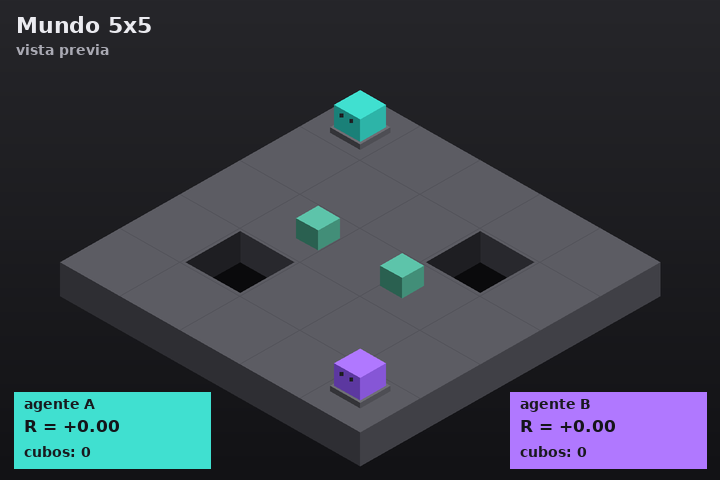

In [5]:
from IPython.display import display
from PIL import Image
_e = ArenaEnv(CFG); _e.reset("demo")
display(Image.fromarray(IsoRenderer(CFG).frame(_e, None, "Mundo 5x5", "vista previa")))

## 4. Agentes PPO independientes (IPPO)

In [6]:
import numpy as np
import torch
import torch.nn as nn
from torch.distributions import Normal

torch.set_num_threads(2)


def _init(m, gain):
    if isinstance(m, nn.Linear):
        nn.init.orthogonal_(m.weight, gain)
        nn.init.zeros_(m.bias)


class ActorCritic(nn.Module):
    def __init__(self, obs_dim, act_dim, hidden, log_std_init):
        super().__init__()
        self.pi = nn.Sequential(nn.Linear(obs_dim, hidden), nn.Tanh(), nn.Linear(hidden, hidden), nn.Tanh(), nn.Linear(hidden, act_dim))
        self.v = nn.Sequential(nn.Linear(obs_dim, hidden), nn.Tanh(), nn.Linear(hidden, hidden), nn.Tanh(), nn.Linear(hidden, 1))
        self.log_std = nn.Parameter(torch.full((act_dim,), float(log_std_init)))
        for net, g in ((self.pi, 0.01), (self.v, 1.0)):
            for m in net[:-1]:
                _init(m, np.sqrt(2))
            _init(net[-1], g)

    def dist(self, x):
        return Normal(self.pi(x), self.log_std.exp())


class PPOAgent:
    """Agente PPO independiente (IPPO): su propia red actor-crítico y su propio buffer.
    La política es gaussiana sobre (ax, ay): acciones continuas en x e y a la vez."""

    def __init__(self, obs_dim, act_dim, cfg, seed):
        self.cfg = cfg
        torch.manual_seed(seed)
        self.ac = ActorCritic(obs_dim, act_dim, cfg.HIDDEN, cfg.LOG_STD_INIT)
        self.opt = torch.optim.Adam(self.ac.parameters(), lr=cfg.LR, eps=1e-5)
        self.clear()

    def clear(self):
        self.obs, self.act, self.logp, self.val, self.rew, self.done = [], [], [], [], [], []
        self.adv, self.ret = [], []
        self.path_start = 0

    @torch.no_grad()
    def act_step(self, obs):
        x = torch.as_tensor(obs, dtype=torch.float32).unsqueeze(0)
        d = self.ac.dist(x)
        a = d.sample()
        return a[0].numpy(), float(d.log_prob(a).sum()), float(self.ac.v(x))

    @torch.no_grad()
    def act_play(self, obs, deterministic=False):
        x = torch.as_tensor(obs, dtype=torch.float32).unsqueeze(0)
        d = self.ac.dist(x)
        a = d.mean if deterministic else d.sample()
        return a[0].numpy()

    def store(self, o, a, lp, v, r, done):
        self.obs.append(o); self.act.append(a); self.logp.append(lp)
        self.val.append(v); self.rew.append(r); self.done.append(float(done))

    def finish_path(self):
        """Calcula GAE de la trayectoria recién terminada (siempre termina en 'done')."""
        c, s, e = self.cfg, self.path_start, len(self.rew)
        if e == s:
            return
        adv = np.zeros(e - s, np.float32)
        last = 0.0
        for t in reversed(range(s, e)):
            nv = self.val[t + 1] if (t + 1 < e) else 0.0
            nonterm = 1.0 - self.done[t]
            delta = self.rew[t] + c.GAMMA * nv * nonterm - self.val[t]
            last = delta + c.GAMMA * c.LAM * nonterm * last
            adv[t - s] = last
        self.adv.extend(adv.tolist())
        self.ret.extend((adv + np.array(self.val[s:e], np.float32)).tolist())
        self.path_start = e

    def update(self):
        c = self.cfg
        if len(self.adv) < 2:
            self.clear(); return
        obs = torch.as_tensor(np.array(self.obs), dtype=torch.float32)
        act = torch.as_tensor(np.array(self.act), dtype=torch.float32)
        logp_old = torch.as_tensor(np.array(self.logp), dtype=torch.float32)
        adv = torch.as_tensor(np.array(self.adv), dtype=torch.float32)
        ret = torch.as_tensor(np.array(self.ret), dtype=torch.float32)
        adv = (adv - adv.mean()) / (adv.std() + 1e-8)
        n = len(obs)
        for _ in range(c.EPOCHS):
            perm = torch.randperm(n)
            for st in range(0, n, c.MINIBATCH):
                i = perm[st:st + c.MINIBATCH]
                d = self.ac.dist(obs[i])
                logp = d.log_prob(act[i]).sum(-1)
                ratio = (logp - logp_old[i]).exp()
                pl = -torch.min(ratio * adv[i], ratio.clamp(1 - c.CLIP, 1 + c.CLIP) * adv[i]).mean()
                vl = ((self.ac.v(obs[i]).squeeze(-1) - ret[i]) ** 2).mean()
                loss = pl + c.VF_COEF * vl - c.ENT_COEF * d.entropy().sum(-1).mean()
                self.opt.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(self.ac.parameters(), c.MAX_GRAD_NORM)
                self.opt.step()
        self.clear()

## 5. Entrenamiento con videos periódicos
Se entrena por lotes de `BATCH_STEPS` pasos; cada `VIDEO_EVERY` episodios se imprime el resumen (quién gana, cuántos episodios terminan con ambos cubos en pozos, caídas) y se muestra un video.
La competencia puede dar dinámicas interesantes: a veces un agente domina, a veces se reparten los cubos y empatan.

In [ ]:
import base64, io, time
import numpy as np
import imageio
import matplotlib.pyplot as plt
from IPython.display import HTML, display

plt.rcParams.update({
    'figure.facecolor': '#2b2b2b', 'axes.facecolor': '#2b2b2b', 'axes.edgecolor': '#cccccc',
    'axes.labelcolor': '#cccccc', 'xtick.color': '#cccccc', 'ytick.color': '#cccccc',
    'text.color': '#cccccc', 'grid.color': '#444444',
})

np.random.seed(CFG.SEED)
env = ArenaEnv(CFG)
renderer = IsoRenderer(CFG)
agents = [PPOAgent(env.obs_dim, env.act_dim, CFG, CFG.SEED + 17 * i) for i in range(2)]
NAMES = ["agente A", "agente B"]


def record_episode(title, layout="demo", deterministic=False):
    """Juega UN episodio (sin entrenar) y devuelve los cuadros del video."""
    obs = env.reset(layout)
    frames = [renderer.frame(env, None, title, "estado inicial") for _ in range(8)]
    for _ in range(CFG.MAX_STEPS):
        acts = [agents[i].act_play(obs[i], deterministic) if env.alive[i] else np.zeros(2) for i in range(2)]
        obs, rew, dones, over, info = env.step(acts)
        for k in range(1, CFG.SUBFRAMES + 1):
            frames.append(renderer.frame(env, k / CFG.SUBFRAMES, title, f"paso {env.t}"))
        if over:
            break
    banner = {"gana0": "¡Gana agente A!", "gana1": "¡Gana agente B!", "empate": "Empate"}[env.result]
    frames += [renderer.frame(env, None, title, f"paso {env.t}", banner) for _ in range(int(CFG.FPS * 1.5))]
    return frames


def show_video(frames, width=540):
    try:
        path = "/tmp/_ep.mp4"
        imageio.mimwrite(path, frames, fps=CFG.FPS, codec="libx264", quality=7, macro_block_size=16)
        b64 = base64.b64encode(open(path, "rb").read()).decode()
        display(HTML(f'<video width="{width}" controls loop autoplay muted>'
                     f'<source src="data:video/mp4;base64,{b64}" type="video/mp4"></video>'))
    except Exception:                                   # plan B: GIF
        from PIL import Image
        ims = [Image.fromarray(f) for f in frames[::2]]
        ims[0].save("/tmp/_ep.gif", save_all=True, append_images=ims[1:], duration=int(2000 / CFG.FPS), loop=0)
        b64 = base64.b64encode(open("/tmp/_ep.gif", "rb").read()).decode()
        display(HTML(f'<img width="{width}" src="data:image/gif;base64,{b64}">'))


def play_training_episode():
    obs = env.reset()
    for _ in range(CFG.MAX_STEPS):
        alive = list(env.alive)
        acts, tr = [], [None, None]
        for i in range(2):
            if alive[i]:
                a, lp, v = agents[i].act_step(obs[i])
                tr[i] = (obs[i], a, lp, v)
                acts.append(np.clip(a, -1, 1))
            else:
                acts.append(np.zeros(2))
        obs2, rew, dones, over, info = env.step(acts)
        for i in range(2):
            if alive[i]:                                   # solo se aprende de lo que vivió cada agente
                agents[i].store(*tr[i], rew[i], dones[i])
        obs = obs2
        if over:
            break
    for ag in agents:
        ag.finish_path()
    return dict(result=env.result, credits=list(env.credits), status=list(env.status),
                ret=list(env.total_reward), steps=env.t)


HIST = []                                                   # historial por episodio


def summary(last):
    L = HIST[-last:]
    n = len(L)
    f = lambda cond: sum(1 for e in L if cond(e)) / n
    return dict(
        turq=f(lambda e: e["result"] == "gana0"), viol=f(lambda e: e["result"] == "gana1"),
        emp=f(lambda e: e["result"] == "empate"),
        todos=f(lambda e: sum(e["credits"]) == 2),
        caidas=np.mean([sum(s != "ok" for s in e["status"]) for e in L]) / 2)


t0 = time.time()
print("▶ Episodio 0 — agentes sin entrenar")
show_video(record_episode("Episodio 0 (sin entrenar)"))

ep, next_video = 0, CFG.VIDEO_EVERY
while ep < CFG.MAX_EPISODES:
    steps = 0
    while steps < CFG.BATCH_STEPS:
        HIST.append(play_training_episode())
        steps += HIST[-1]["steps"]
        ep += 1
    for ag in agents:
        ag.update()
    if ep >= next_video:
        s = summary(CFG.VIDEO_EVERY)
        print(f"▶ Episodio {ep} | gana agente A {s['turq']:.0%} | gana agente B {s['viol']:.0%} | empate {s['emp']:.0%} | "
              f"ambos cubos en pozos {s['todos']:.0%} | caídas/agente {s['caidas']:.2f} | {time.time()-t0:.0f}s")
        show_video(record_episode(f"Episodio {ep}  (T {s['turq']:.0%} · V {s['viol']:.0%} · E {s['emp']:.0%})"))
        while next_video <= ep:
            next_video += CFG.VIDEO_EVERY

# ---- curvas ----
w = 100
def roll(key_fn):
    x = np.array([key_fn(e) for e in HIST], float)
    return np.convolve(x, np.ones(w) / w, mode="valid")
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for lab, fn, col in (("gana agente A", lambda e: e["result"] == "gana0", "#40e0d0"),
                     ("gana agente B", lambda e: e["result"] == "gana1", "#b078ff"),
                     ("empate", lambda e: e["result"] == "empate", "#999999")):
    ax[0].plot(roll(fn), label=lab, color=col)
ax[0].set_title("Resultados (media móvil 100)"); ax[0].legend(); ax[0].set_ylim(-0.02, 1.02)
ax[1].plot(roll(lambda e: sum(e["credits"]) == 2), color="#5dc4aa")
ax[1].set_title("Episodios con ambos cubos en pozos"); ax[1].set_ylim(-0.02, 1.02)
for i, col in enumerate(("#40e0d0", "#b078ff")):
    ax[2].plot(roll(lambda e, i=i: e["ret"][i]), color=col, label=NAMES[i])
ax[2].set_title("Retorno por episodio"); ax[2].legend()
for a in ax:
    a.set_xlabel("episodio"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

▶ Episodio 0 — agentes sin entrenar


▶ Episodio 515 | gana agente A 3% | gana agente B 3% | empate 95% | ambos cubos en pozos 0% | caídas/agente 0.24 | 157s


## 6. Probar con cubos en posiciones al azar

In [ ]:
for k in range(3):
    show_video(record_episode(f"Prueba {k+1} (cubos al azar)", layout=None))

## Ideas para experimentar
- `WIN_REWARD` alto y `DROP_REWARD` bajo → más agresivos; `DROP_REWARD` alto → tienden a conformarse con el empate.
- `K_APPROACH = 0` y `K_PUSH = 0` quitan el shaping: aprender cuesta mucho más.
- `R_BOX` cerca de `HOLE_SIZE/2` hace que embocar sea casi imposible (por eso los cubos son chicos).
- `VMAX` más alto = movimientos más bruscos; `SUBFRAMES` y `FPS` cambian la velocidad del video.
- Cambiá `SEED`: en esta competencia el resultado puede variar (quién domina).